# Laboratorio 5 — Ejercicio 2: Berlin52

Este cuaderno aplica un algoritmo genético al problema del agente viajero **Berlin52**. La instancia contiene 52 ciudades y su mejor distancia conocida y demostrada es **7542**. El propósito es obtener una solución reproducible, comparar su distancia con ese óptimo y guardar tanto los datos numéricos como las visualizaciones.

## Objetivo

Se busca una permutación de las 52 ciudades que minimice la longitud del ciclo cerrado. Cada ciudad debe aparecer exactamente una vez y, al evaluar la solución, se incluye el regreso desde la última ciudad a la primera. Para evitar depender de una sola corrida aleatoria, se ejecutan varias semillas fijas y se conserva la de menor distancia.

## Metodología y criterio de distancia

La entrada se lee desde `berlin52.tsp`. Según TSPLIB, esta instancia usa el tipo de arista **EUC_2D**: primero se calcula la distancia euclidiana entre dos coordenadas y luego se redondea al entero más cercano con $\lfloor d + 0.5 \rfloor$. Por ello, no se deben sumar distancias euclidianas sin redondear.

El algoritmo usa selección por torneo, cruce OX, mutación por inversión, elitismo y control de duplicados. El solucionador también aplica una mejora local acotada a las mejores soluciones encontradas.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

try:
    from Ejercicio_2.berlin52_ga import ejecutar_experimentos, leer_tsplib
except ModuleNotFoundError:
    # Permite ejecutar el cuaderno con Ejercicio_2 como directorio de trabajo.
    from berlin52_ga import ejecutar_experimentos, leer_tsplib

## Configuración reproducible

Se usan tres semillas explícitas. Una población de 120 individuos durante 300 generaciones ofrece un balance razonable entre exploración y tiempo de ejecución para 52 ciudades. Las proporciones dejan un pequeño espacio para inmigrantes aleatorios, lo que ayuda a conservar diversidad.

In [2]:
DIRECTORIO_ACTUAL = Path.cwd()
DIRECTORIO_SALIDA = (
    DIRECTORIO_ACTUAL / "Ejercicio_2"
    if (DIRECTORIO_ACTUAL / "Ejercicio_2" / "berlin52.tsp").exists()
    else DIRECTORIO_ACTUAL
)
RUTA_DATOS = DIRECTORIO_SALIDA / "berlin52.tsp"
OPTIMO = 7542
semillas = [5, 7, 42]
parametros = {
    "N": 120,
    "max_iter": 300,
    "seleccion": "torneo",
    "k": 4,
    "s": 0.05,
    "c": 0.70,
    "m": 0.20,
}

coordenadas, metadatos = leer_tsplib(RUTA_DATOS)
print(f"Instancia: {metadatos['NAME']} ({len(coordenadas)} ciudades)")
print(f"Tipo de distancia: {metadatos['EDGE_WEIGHT_TYPE']}")
print(f"Semillas: {semillas}")
print(f"Parámetros: {parametros}")

Instancia: berlin52 (52 ciudades)
Tipo de distancia: EUC_2D
Semillas: [5, 7, 42]
Parámetros: {'N': 120, 'max_iter': 300, 'seleccion': 'torneo', 'k': 4, 's': 0.05, 'c': 0.7, 'm': 0.2}


## Resultados

La siguiente celda ejecuta las tres corridas y selecciona automáticamente la que tenga la menor distancia. La ruta se transforma de índices internos basados en cero a identificadores de ciudad basados en uno, y se repite la primera ciudad al final para mostrar explícitamente que el recorrido es cerrado.

In [3]:
mejor, resultados = ejecutar_experimentos(
    coordenadas, semillas, **parametros
)

ruta_una_base = [int(ciudad) + 1 for ciudad in mejor.recorrido]
ruta_cerrada = ruta_una_base + [ruta_una_base[0]]
gap = int(mejor.distancia) - OPTIMO
gap_porcentual = 100.0 * gap / OPTIMO

for resultado in resultados:
    print(f"Semilla {resultado.semilla:>2}: distancia = {resultado.distancia}")
print(f"\nMejor semilla: {mejor.semilla}")
print("Ruta cerrada (IDs 1-based):")
print(" -> ".join(map(str, ruta_cerrada)))
print(f"Distancia: {mejor.distancia}")
print(f"Óptimo de referencia: {OPTIMO}")
print(f"Gap: {gap} ({gap_porcentual:.2f} %)")

Semilla  5: distancia = 7542
Semilla  7: distancia = 7667
Semilla 42: distancia = 7627

Mejor semilla: 5
Ruta cerrada (IDs 1-based):
31 -> 22 -> 1 -> 49 -> 32 -> 45 -> 19 -> 41 -> 8 -> 9 -> 10 -> 43 -> 33 -> 51 -> 11 -> 52 -> 14 -> 13 -> 47 -> 26 -> 27 -> 28 -> 12 -> 25 -> 4 -> 6 -> 15 -> 5 -> 24 -> 48 -> 38 -> 37 -> 40 -> 39 -> 36 -> 35 -> 34 -> 44 -> 46 -> 16 -> 29 -> 50 -> 20 -> 23 -> 30 -> 2 -> 7 -> 42 -> 21 -> 17 -> 3 -> 18 -> 31
Distancia: 7542
Óptimo de referencia: 7542
Gap: 0 (0.00 %)


In [4]:
resumen = {
    "instancia": metadatos["NAME"],
    "tipo_distancia": metadatos["EDGE_WEIGHT_TYPE"],
    "optimo": OPTIMO,
    "semillas": semillas,
    "parametros": parametros,
    "mejor_semilla": int(mejor.semilla),
    "mejor_distancia": int(mejor.distancia),
    "gap_absoluto": gap,
    "gap_porcentual": gap_porcentual,
    "ruta_1_based_cerrada": ruta_cerrada,
    "corridas": [
        {"semilla": int(r.semilla), "distancia": int(r.distancia)}
        for r in resultados
    ],
}
RUTA_RESULTADOS = DIRECTORIO_SALIDA / "resultados_berlin52.json"
RUTA_RESULTADOS.write_text(
    json.dumps(resumen, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print(f"Resultados guardados en: {RUTA_RESULTADOS}")

Resultados guardados en: C:\Users\anna2\Desktop\UVG\Modelacion y simulacion\Lab_5_Modelacion\Ejercicio_2\resultados_berlin52.json


## Visualización

Se guardan dos figuras. La primera muestra el ciclo de la mejor solución sobre las coordenadas originales. La segunda compara la mejor distancia acumulada de cada semilla y agrega una línea horizontal en 7542 para facilitar la comparación con el óptimo.

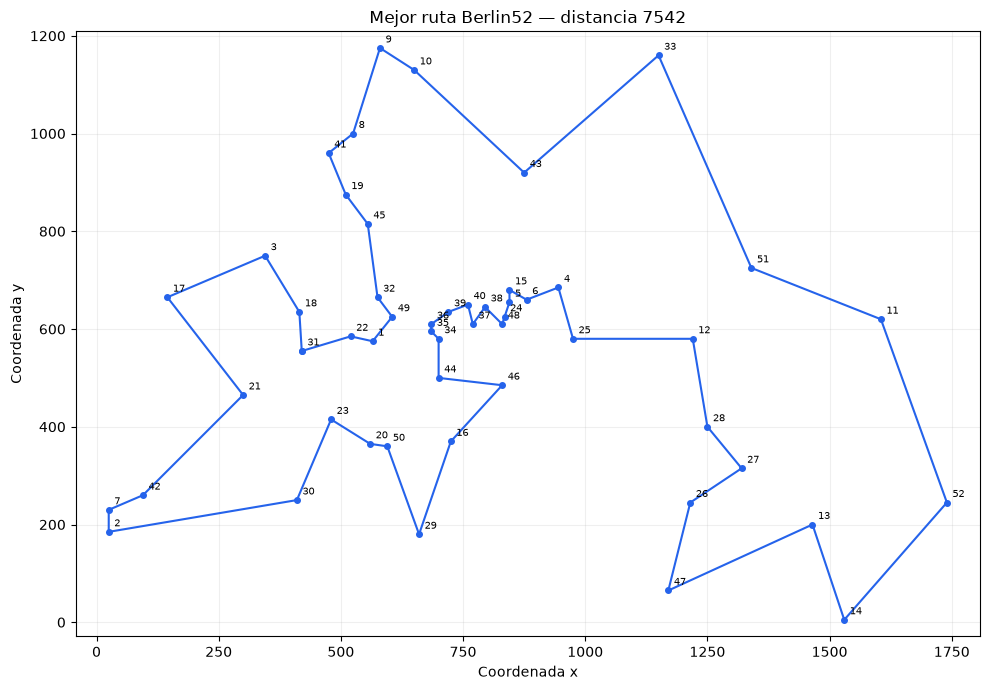

Ruta guardada en: C:\Users\anna2\Desktop\UVG\Modelacion y simulacion\Lab_5_Modelacion\Ejercicio_2\mejor_ruta_berlin52.png


In [5]:
indices_cerrados = np.append(mejor.recorrido, mejor.recorrido[0])
puntos_ruta = coordenadas[indices_cerrados]

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(puntos_ruta[:, 0], puntos_ruta[:, 1], "-o", color="#2563eb",
        linewidth=1.5, markersize=4)
for identificador, (x, y) in enumerate(coordenadas, start=1):
    ax.annotate(str(identificador), (x, y), xytext=(4, 4),
                textcoords="offset points", fontsize=7)
ax.set_title(f"Mejor ruta Berlin52 — distancia {mejor.distancia}")
ax.set_xlabel("Coordenada x")
ax.set_ylabel("Coordenada y")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.2)
fig.tight_layout()
RUTA_FIGURA = DIRECTORIO_SALIDA / "mejor_ruta_berlin52.png"
fig.savefig(RUTA_FIGURA, dpi=160, bbox_inches="tight")
plt.show()
print(f"Ruta guardada en: {RUTA_FIGURA}")

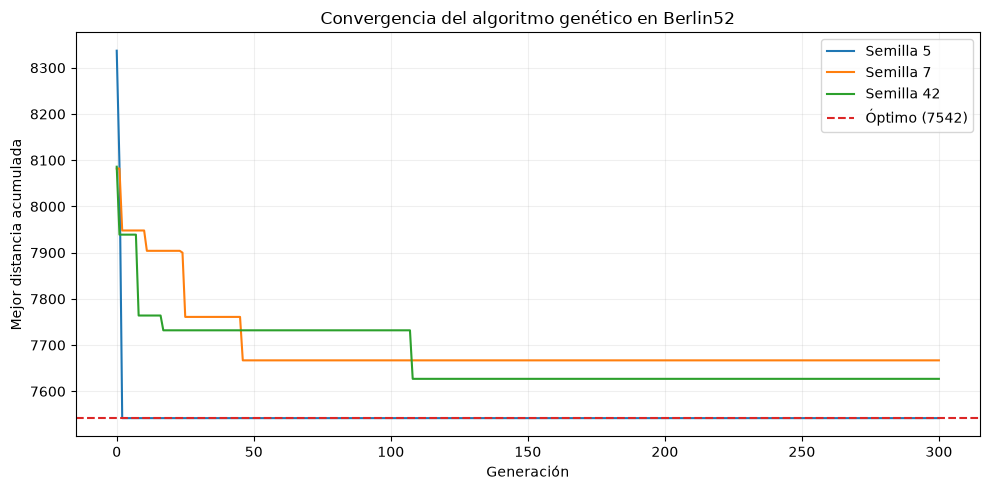

Convergencia guardada en: C:\Users\anna2\Desktop\UVG\Modelacion y simulacion\Lab_5_Modelacion\Ejercicio_2\convergencia_berlin52.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for resultado in resultados:
    generaciones = np.arange(len(resultado.historial_mejor))
    ax.plot(generaciones, resultado.historial_mejor, linewidth=1.5,
            label=f"Semilla {resultado.semilla}")
ax.axhline(OPTIMO, color="#dc2626", linestyle="--", linewidth=1.5,
           label=f"Óptimo ({OPTIMO})")
ax.set_title("Convergencia del algoritmo genético en Berlin52")
ax.set_xlabel("Generación")
ax.set_ylabel("Mejor distancia acumulada")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
RUTA_CONVERGENCIA = DIRECTORIO_SALIDA / "convergencia_berlin52.png"
fig.savefig(RUTA_CONVERGENCIA, dpi=160, bbox_inches="tight")
plt.show()
print(f"Convergencia guardada en: {RUTA_CONVERGENCIA}")

## Conclusión

El experimento permite cuantificar directamente la calidad de la mejor solución mediante su gap respecto de 7542. En esta ejecución se obtuvo un **gap de cero**, por lo que el algoritmo alcanzó el óptimo de Berlin52. El uso de semillas y parámetros explícitos hace que todas las corridas sean repetibles. Los archivos `resultados_berlin52.json`, `mejor_ruta_berlin52.png` y `convergencia_berlin52.png` dejan evidencia reutilizable del resultado al ejecutar el cuaderno.